# ⚡ Visualisation des données – Consommation annuelle par IRIS

**Projet :** Impact de l'IA générative
**Source :** [data.gouv.fr – Défis](https://defis.data.gouv.fr/datasets/5a142ae9a3a7297774073454)
**Fichier :** `consommation-annuelle-par-iris.csv`

Ce notebook est organisé en 6 parties :

1. Imports et paramètres
2. Chargement des données
3. Aperçu général
4. Qualité des données (valeurs manquantes, doublons)
5. Statistiques descriptives
6. Visualisations

> 💡 Les colonnes importantes (année, consommation, secteur…) sont **détectées automatiquement**.
> Si une détection est fausse, corrigez-la dans la partie 2 (cellule « Choix des colonnes »).

## 1. Imports et paramètres

In [1]:
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Affichage
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# Chemin du fichier : le notebook est dans le dossier Data, à côté du CSV
from pathlib import Path
CHEMIN_CSV = Path("consommation-annuelle-par-iris.csv")
if not CHEMIN_CSV.exists():
    CHEMIN_CSV = Path("Data/consommation-annuelle-par-iris.csv")  # si lancé depuis la racine du projet
print("Fichier utilisé :", CHEMIN_CSV.resolve())

Fichier utilisé : C:\Users\dufau\Documents\GitHub\Projet_Impact_IA_Generative\Data\consommation-annuelle-par-iris.csv


## 2. Chargement des données

Le séparateur du CSV (`;` ou `,`) est détecté automatiquement.
Les noms de colonnes sont ensuite « nettoyés » (minuscules, sans accents, sans espaces) pour faciliter leur utilisation.

In [2]:
# Détection du séparateur à partir de la première ligne
with open(CHEMIN_CSV, encoding="utf-8", errors="replace") as f:
    premiere_ligne = f.readline()
separateur = ";" if premiere_ligne.count(";") > premiere_ligne.count(",") else ","
print(f"Séparateur détecté : '{separateur}'")

df = pd.read_csv(CHEMIN_CSV, sep=separateur, low_memory=False)


def nettoyer_nom(nom):
    """'Consommation (MWh)' -> 'consommation_mwh'"""
    nom = unicodedata.normalize("NFKD", str(nom)).encode("ascii", "ignore").decode()
    nom = re.sub(r"[^0-9a-zA-Z]+", "_", nom).strip("_").lower()
    return nom


df.columns = [nettoyer_nom(c) for c in df.columns]
print(f"{df.shape[0]:,} lignes × {df.shape[1]} colonnes")
list(df.columns)

Séparateur détecté : ';'
17,891 lignes × 18 colonnes


['annee',
 'code_iris',
 'consommation_gaz_mwh_grtgaz',
 'pdl_gaz_grtgaz',
 'consommation_gaz_mwh_terega',
 'pdl_gaz_terega',
 'consommation_electricite_mwh_rte',
 'pdl_electricite_rte',
 'consommation_totale_mwh',
 'pdl_total',
 'code_insee_commune',
 'commune',
 'code_insee_departement',
 'departement',
 'code_insee_region',
 'region',
 'geo_shape_iris',
 'geo_point_iris']

In [3]:
# --- Choix des colonnes ---------------------------------------------------
# Détection automatique par mots-clés. Remplacez None par un nom de colonne
# (ex : "annee") si la détection ne convient pas.

def trouver_colonne(mots_cles, exclure=()):
    """Retourne la première colonne dont le nom contient un des mots-clés."""
    for mot in mots_cles:
        for col in df.columns:
            if mot in col and not any(e in col for e in exclure):
                return col
    return None

COL_ANNEE    = None or trouver_colonne(["annee", "year"])
COL_CONSO    = None or trouver_colonne(["conso", "mwh"], exclure=["moyenne", "moy", "nb", "nombre"])
COL_POINTS   = None or trouver_colonne(["nombre_de_points", "nb_points", "nombre_points", "points"])
COL_FILIERE  = None or trouver_colonne(["filiere", "energie"])
COL_SECTEUR  = None or trouver_colonne(["secteur", "grand_secteur", "categorie"])
COL_REGION   = None or trouver_colonne(["nom_region", "region"])
COL_DEPART   = None or trouver_colonne(["nom_departement", "departement"])
COL_COMMUNE  = None or trouver_colonne(["nom_commune", "commune"])

colonnes_detectees = {
    "Année": COL_ANNEE, "Consommation": COL_CONSO, "Nb points": COL_POINTS,
    "Filière": COL_FILIERE, "Secteur": COL_SECTEUR, "Région": COL_REGION,
    "Département": COL_DEPART, "Commune": COL_COMMUNE,
}
pd.DataFrame(colonnes_detectees.items(), columns=["Rôle", "Colonne détectée"])

,Rôle,Colonne détectée
0,Année,annee
1,Consommation,consommation_gaz_mwh_grtgaz
2,Nb points,None
3,Filière,None
4,Secteur,None
5,Région,code_insee_region
6,Département,code_insee_departement
7,Commune,code_insee_commune


## 3. Aperçu général

In [4]:
df.head(10)

,annee,code_iris,consommation_gaz_mwh_grtgaz,pdl_gaz_grtgaz,consommation_gaz_mwh_terega,pdl_gaz_terega,consommation_electricite_mwh_rte,pdl_electricite_rte,consommation_totale_mwh,pdl_total,code_insee_commune,commune,code_insee_departement,departement,code_insee_region,region,geo_shape_iris,geo_point_iris
0,"2,012.00",091100000,0.00,0.00,0.00,0.00,"40,887.45",2.00,"40,887.45",2.00,"9,110.00",Encourtiech,9.00,Ariège,76.00,Occitanie,"{""coordinates"": [[[[1.1999046605, 42.973221576...","42.9636434451, 1.1927315206"
1,"2,012.00",130560101,"1,214,891.53",4.00,0.00,0.00,0.00,0.00,"1,214,891.53",4.00,"13,056.00",Martigues,13.00,Bouches-du-Rhône,93.00,Provence-Alpes-Côte d'Azur,"{""coordinates"": [[[[5.0103480211, 43.365544465...","43.3409326104, 5.051164827"
2,"2,012.00",131020103,0.00,0.00,0.00,0.00,"10,146.44",1.00,"10,146.44",1.00,"13,102.00",Saint-Victoret,13.00,Bouches-du-Rhône,93.00,Provence-Alpes-Côte d'Azur,"{""coordinates"": [[[[5.2537205925, 43.410216033...","43.4109475346, 5.2630319615"
3,"2,012.00",144370105,0.00,0.00,0.00,0.00,"20,730.22",1.00,"20,730.22",1.00,"14,437.00",Mondeville,14.00,Calvados,28.00,Normandie,"{""coordinates"": [[[[-0.2966773306, 49.17331196...","49.1609660193, -0.3023333437"
4,"2,012.00",300320102,0.00,0.00,0.00,0.00,"103,254.68",2.00,"103,254.68",2.00,"30,032.00",Beaucaire,30.00,Gard,76.00,Occitanie,"{""coordinates"": [[[[4.6231462282, 43.807972197...","43.8030317374, 4.5846023921"
5,"2,012.00",312460000,0.00,0.00,0.00,0.00,"2,826.08",1.00,"2,826.08",1.00,"31,246.00",Labarthe-Inard,31.00,Haute-Garonne,76.00,Occitanie,"{""coordinates"": [[[[0.8298413265, 43.091979179...","43.1080225352, 0.832512802"
6,"2,012.00",315555001,0.00,0.00,"22,870.39",1.00,"9,119.64",2.00,"31,990.03",3.00,"31,555.00",Toulouse,31.00,Haute-Garonne,76.00,Occitanie,"{""coordinates"": [[[[1.3948923956, 43.559941799...","43.5541724943, 1.416444634"
7,"2,012.00",341460000,0.00,0.00,0.00,0.00,"12,240.64",1.00,"12,240.64",1.00,"34,146.00",Lunel-Viel,34.00,Hérault,76.00,Occitanie,"{""coordinates"": [[[[4.0779752657, 43.662624368...","43.6825590766, 4.0842199059"
8,"2,012.00",021860000,0.00,0.00,0.00,0.00,"18,074.08",1.00,"18,074.08",1.00,"2,186.00",Chézy-sur-Marne,2.00,Aisne,32.00,Hauts-de-France,"{""coordinates"": [[[[3.3478959035, 48.960986326...","48.9844182584, 3.3823334703"
9,"2,012.00",027460000,390.87,1.00,0.00,0.00,0.00,0.00,390.87,1.00,"2,746.00",Travecy,2.00,Aisne,32.00,Hauts-de-France,"{""coordinates"": [[[[3.3148422356, 49.678153930...","49.6855936899, 3.3451728599"


In [5]:
# Types des colonnes et mémoire utilisée
infos = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "valeurs_uniques": df.nunique(),
    "exemple": df.iloc[0],
})
print(f"Mémoire utilisée : {df.memory_usage(deep=True).sum() / 1e6:.1f} Mo")
infos

Mémoire utilisée : 100.6 Mo


,type,valeurs_uniques,exemple
annee,float64,12,"2,012.00"
code_iris,object,1889,091100000
consommation_gaz_mwh_grtgaz,float64,7602,0.00
pdl_gaz_grtgaz,float64,9,0.00
consommation_gaz_mwh_terega,float64,1229,0.00
pdl_gaz_terega,float64,4,0.00
consommation_electricite_mwh_rte,float64,11338,"40,887.45"
pdl_electricite_rte,float64,12,2.00
consommation_totale_mwh,float64,14633,"40,887.45"
pdl_total,float64,17,2.00


## 4. Qualité des données

Lignes dupliquées : 0


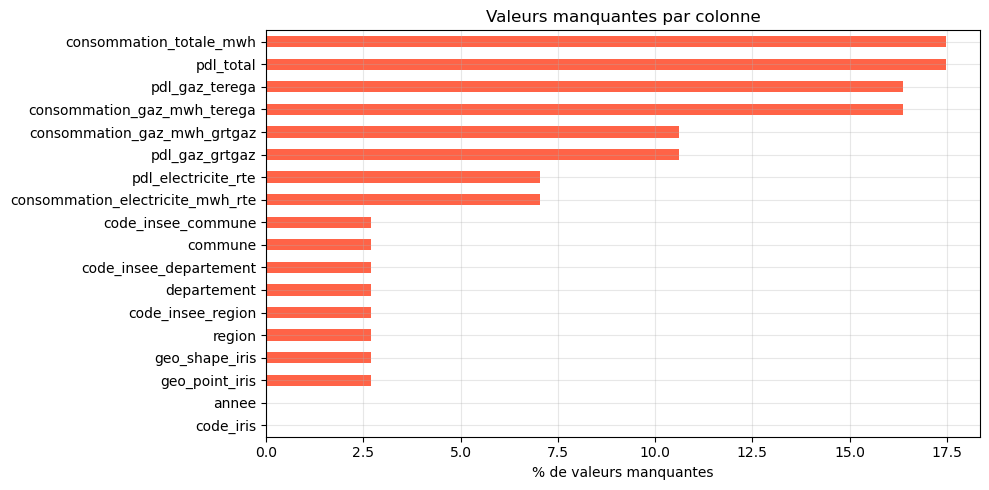

In [6]:
# Valeurs manquantes par colonne
manquantes = (df.isna().mean() * 100).sort_values(ascending=False)
manquantes = manquantes[manquantes > 0]

print(f"Lignes dupliquées : {df.duplicated().sum():,}")

if manquantes.empty:
    print("Aucune valeur manquante 🎉")
else:
    ax = manquantes.sort_values().plot.barh(color="tomato")
    ax.set_xlabel("% de valeurs manquantes")
    ax.set_title("Valeurs manquantes par colonne")
    plt.tight_layout()
    plt.show()

## 5. Statistiques descriptives

In [7]:
# Colonnes numériques
df.describe().T

,count,mean,std,min,25%,50%,75%,max
annee,"17,889.00","2,017.53",3.49,"2,012.00","2,014.00","2,018.00","2,021.00","2,023.00"
consommation_gaz_mwh_grtgaz,"15,991.00","124,434.34","621,230.87",0.00,0.00,0.00,"55,118.01","16,528,876.82"
pdl_gaz_grtgaz,"15,991.00",0.64,0.87,0.00,0.00,0.00,1.00,8.00
consommation_gaz_mwh_terega,"14,961.00","4,053.17","29,179.07",0.00,0.00,0.00,0.00,"847,065.01"
pdl_gaz_terega,"14,961.00",0.09,0.33,0.00,0.00,0.00,0.00,3.00
consommation_electricite_mwh_rte,"16,629.00","44,500.99","171,548.65",0.00,0.00,"4,075.32","29,956.23","4,450,412.05"
pdl_electricite_rte,"16,629.00",0.89,0.89,0.00,0.00,1.00,1.00,11.00
consommation_totale_mwh,"14,764.00","159,738.12","670,032.86",0.00,"4,892.61","23,207.80","98,876.91","17,776,947.30"
pdl_total,"14,764.00",1.51,1.17,0.00,1.00,1.00,2.00,16.00
code_insee_commune,"17,406.00","51,888.70","25,528.04","1,004.00","31,490.00","56,246.00","72,306.00","95,680.00"


In [8]:
# Colonnes textuelles : valeurs les plus fréquentes
cols_texte = df.select_dtypes(include="object").columns
resume_texte = pd.DataFrame({
    "valeurs_uniques": df[cols_texte].nunique(),
    "plus_frequente": [df[c].mode().iat[0] if df[c].notna().any() else None for c in cols_texte],
})
resume_texte

,valeurs_uniques,plus_frequente
code_iris,1889,110490000
commune,1518,Paris
departement,93,Nord
region,12,Nouvelle-Aquitaine
geo_shape_iris,3045,"{""coordinates"": [[[[-0.247229947, 43.254293458..."
geo_point_iris,3041,"43.287970274, 5.495060615"


## 6. Visualisations

Chaque graphique ne s'affiche que si la colonne nécessaire a été détectée.

### 6.1 Distribution de la consommation

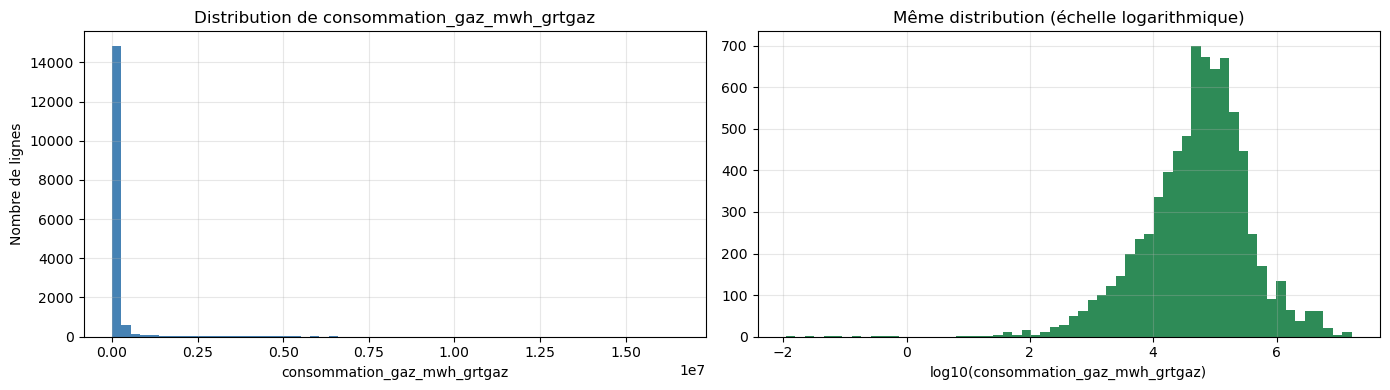

In [9]:
if COL_CONSO:
    conso = pd.to_numeric(df[COL_CONSO], errors="coerce").dropna()
    conso_pos = conso[conso > 0]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].hist(conso, bins=60, color="steelblue")
    axes[0].set_title(f"Distribution de {COL_CONSO}")
    axes[0].set_xlabel(COL_CONSO)
    axes[0].set_ylabel("Nombre de lignes")

    axes[1].hist(np.log10(conso_pos), bins=60, color="seagreen")
    axes[1].set_title("Même distribution (échelle logarithmique)")
    axes[1].set_xlabel(f"log10({COL_CONSO})")
    plt.tight_layout()
    plt.show()
else:
    print("Colonne de consommation non détectée : renseignez COL_CONSO.")

### 6.2 Évolution dans le temps

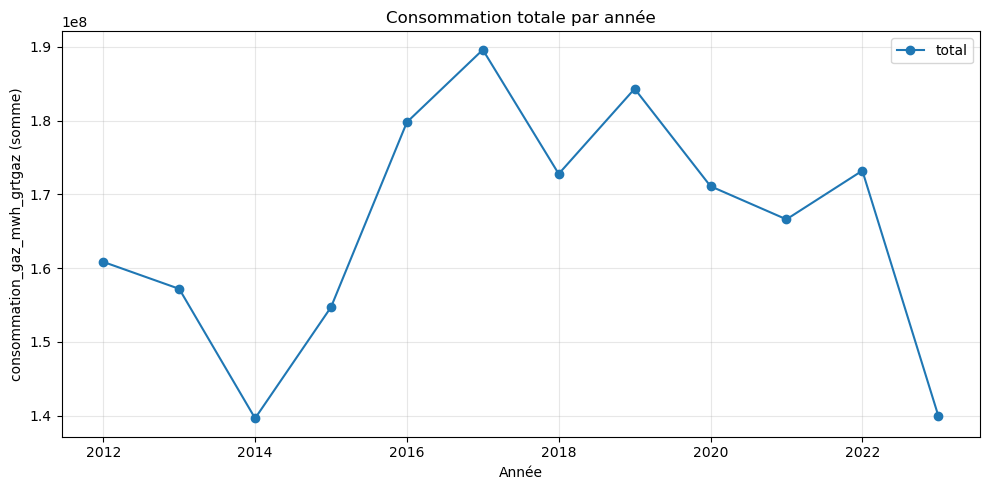

In [10]:
if COL_ANNEE and COL_CONSO:
    if COL_FILIERE:
        evol = df.pivot_table(index=COL_ANNEE, columns=COL_FILIERE, values=COL_CONSO, aggfunc="sum")
    else:
        evol = df.groupby(COL_ANNEE)[COL_CONSO].sum().to_frame("total")

    ax = evol.plot(marker="o")
    ax.set_title("Consommation totale par année")
    ax.set_ylabel(COL_CONSO + " (somme)")
    ax.set_xlabel("Année")
    plt.tight_layout()
    plt.show()
else:
    print("Colonnes année / consommation non détectées.")

### 6.3 Répartition par secteur d'activité

In [11]:
if COL_SECTEUR and COL_CONSO:
    par_secteur = df.groupby(COL_SECTEUR)[COL_CONSO].sum().sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    par_secteur.sort_values().plot.barh(ax=axes[0], color="steelblue")
    axes[0].set_title("Consommation par secteur")
    axes[0].set_xlabel(COL_CONSO + " (somme)")

    axes[1].pie(par_secteur, labels=par_secteur.index, autopct="%1.1f%%", startangle=90)
    axes[1].set_title("Part de chaque secteur")
    axes[1].grid(False)
    plt.tight_layout()
    plt.show()
else:
    print("Colonnes secteur / consommation non détectées.")

Colonnes secteur / consommation non détectées.


### 6.4 Classement géographique (Top 10)

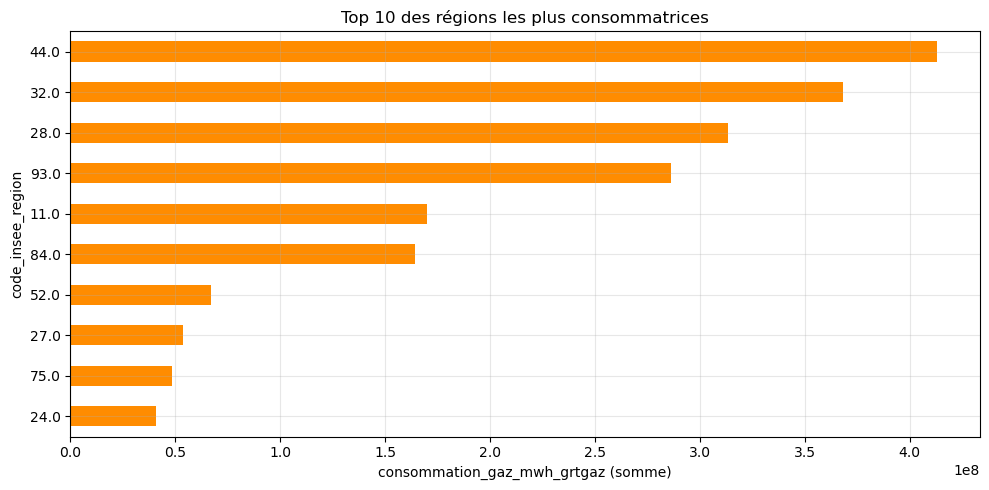

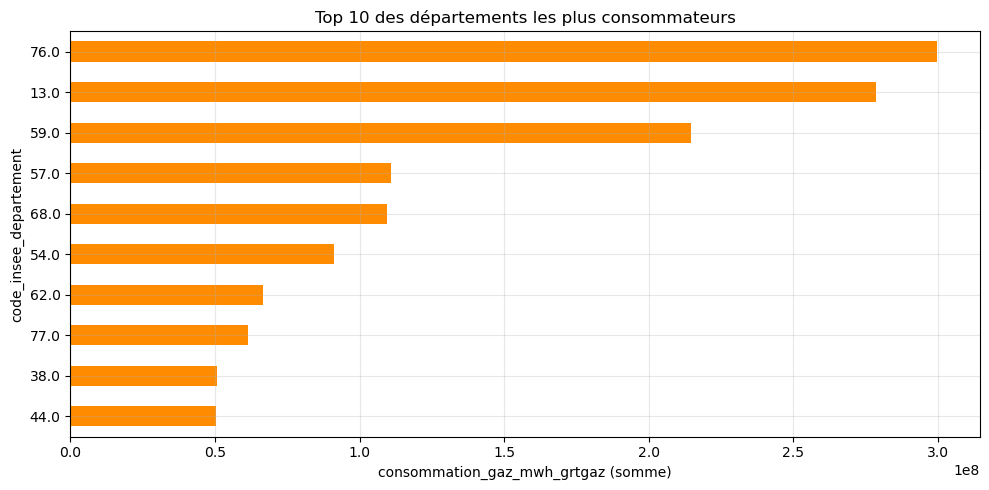

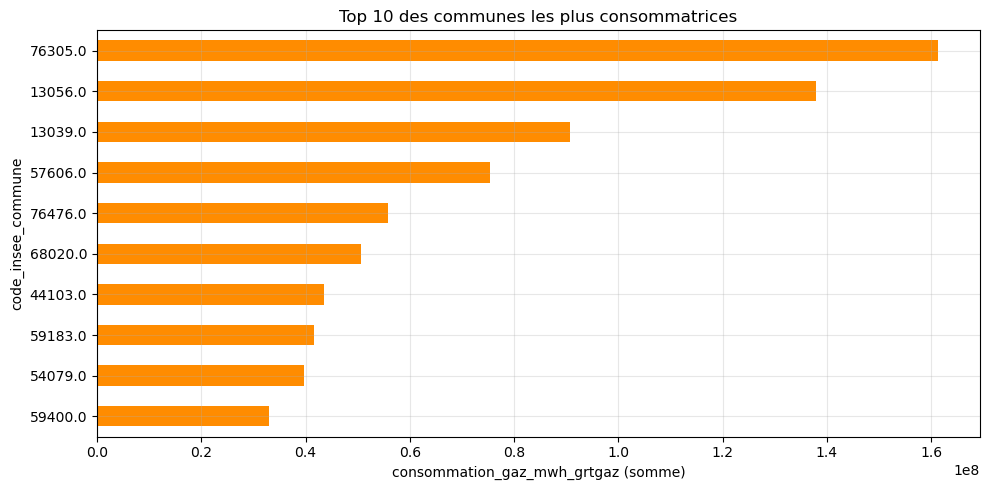

In [12]:
def top_n(col_geo, titre, n=10):
    if col_geo and COL_CONSO:
        top = df.groupby(col_geo)[COL_CONSO].sum().sort_values(ascending=False).head(n)
        ax = top.sort_values().plot.barh(color="darkorange")
        ax.set_title(titre)
        ax.set_xlabel(COL_CONSO + " (somme)")
        plt.tight_layout()
        plt.show()
    else:
        print(f"{titre} : colonne non détectée.")

top_n(COL_REGION, "Top 10 des régions les plus consommatrices")
top_n(COL_DEPART, "Top 10 des départements les plus consommateurs")
top_n(COL_COMMUNE, "Top 10 des communes les plus consommatrices")

### 6.5 Consommation vs nombre de points de livraison

In [14]:
if COL_POINTS and COL_CONSO:
    echantillon = df[[COL_POINTS, COL_CONSO]].apply(pd.to_numeric, errors="coerce").dropna()
    echantillon = echantillon[(echantillon > 0).all(axis=1)]
    echantillon = echantillon.sample(min(len(echantillon), 20000), random_state=0)

    plt.scatter(echantillon[COL_POINTS], echantillon[COL_CONSO], s=5, alpha=0.3)
    plt.xscale("log"); plt.yscale("log")
    plt.xlabel(COL_POINTS + " (log)")
    plt.ylabel(COL_CONSO + " (log)")
    plt.title("Consommation vs nombre de points (échantillon, échelles log)")
    plt.tight_layout()
    plt.show()
else:
    print("Colonnes points / consommation non détectées.")

Colonnes points / consommation non détectées.


### 6.6 Corrélations entre variables numériques

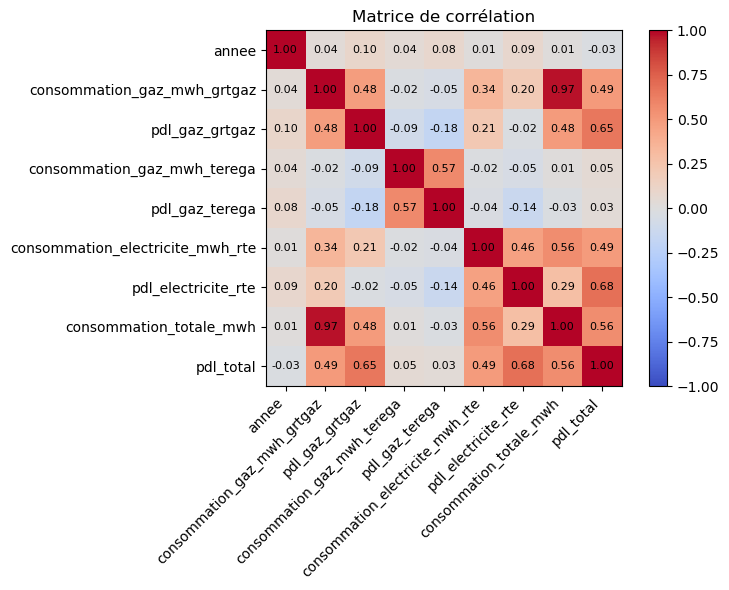

In [15]:
num = df.select_dtypes(include="number")
# On retire les colonnes de type "code" (identifiants) qui n'ont pas de sens ici
num = num[[c for c in num.columns if not c.startswith("code")]]

if num.shape[1] >= 2:
    corr = num.corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    ax.grid(False)
    fig.colorbar(im)
    ax.set_title("Matrice de corrélation")
    plt.tight_layout()
    plt.show()
else:
    print("Pas assez de colonnes numériques.")

## ✅ Et ensuite ?

- Filtrer sur une région ou un département précis pour zoomer.
- Croiser avec d'autres jeux de données du défi (ex. : données sur les data centers ou l'usage de l'IA).
- Sauvegarder un fichier nettoyé : `df.to_csv("consommation_nettoyee.csv", index=False)`.